## this script calculates the conditional probability that given the first (last) author comes from a given group, the possiblity that the middle author comes from a specific group

In [1]:
import pandas as pd
from time import time
import numpy as np
import tqdm
import seaborn as sns
import itertools
import matplotlib.pyplot as plt

In [2]:
pub_detail_path='../../data/dropbox/LaborDivision/Data/deriveddata/pub_detail.pkl'
author_path='../../data/dropbox/LaborDivision/Data/deriveddata/authors_ordered.pkl'
author_info_path='../../data/dropbox/LaborDivision/Data/cleanedraw/author_info.pkl'
ingroup_path = '../../data/dropbox/LaborDivision/Data/additionaldata/cntry_classification/cntry_group_meta.csv'

In [3]:
author_all=pd.read_pickle(author_path)
author_all.head()

,id,year,dis,cluster_id,role,Code
0,29768068,2008,56,1306275,F,CAN
1,29768068,2008,56,1680670,M,CAN
2,29768068,2008,56,28261869,L,CAN
3,29768070,2008,51,20009795,F,JPN
4,29768070,2008,51,29411586,M,JPN


In [4]:
ingroup_df=pd.read_csv(ingroup_path)
ingroup_df=ingroup_df[['Code','ST']]
ingroup_df=ingroup_df.drop_duplicates()
ingroup_df=ingroup_df.replace(to_replace={'ST':{'Others':'Lagging'}})
ingroup_df.head()

,Code,ST
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [5]:
author_all = author_all.merge(ingroup_df, on='Code')
author_all.head()

,id,year,dis,cluster_id,role,Code,ST
0,29768068,2008,56,1306275,F,CAN,Advanced
1,29768068,2008,56,1680670,M,CAN,Advanced
2,29768068,2008,56,28261869,L,CAN,Advanced
3,29768123,2008,68,56577565,F,CAN,Advanced
4,29768123,2008,68,53978137,M,CAN,Advanced


In [6]:
def return_denominator_papers(df, role, group):
    #return number of pubs that the first (last) author comes from a specific group
    return df[(df.role==role)&(df.ST==group)]['id'].unique()

In [7]:
def return_numerator(df, demoninator_papers, role, ngroup):
    
    denominator_df = df[df['id'].isin(denominator_papers)]
    numerator_df = denominator_df[(denominator_df.role==role)&(denominator_df.ST==ngroup)]
    
    return len(numerator_df['id'].unique())

In [8]:
stgroups = author_all.ST.unique()

In [9]:
middle = []
last = []
for dgroup in stgroups:
    
    denominator_papers = return_denominator_papers(author_all, 'F',dgroup)
    denominator_cnt = len(denominator_papers)
    
    for ngroup in stgroups:
        
        numerator_middle = return_numerator(author_all, denominator_papers, 'M', ngroup)
        pcond_middle = numerator_middle/denominator_cnt
        middle.append([dgroup, ngroup, pcond_middle])

        numerator_last = return_numerator(author_all, denominator_papers, 'L', ngroup)
        pcond_last = numerator_last/denominator_cnt
        last.append([dgroup,ngroup,pcond_last])
       

In [10]:
def structure_resdf(reslist, columns, col_order=['Advanced','Proficient','Developing','Lagging']):
    df = pd.DataFrame(reslist, columns=columns)
    df = df.pivot(index=columns[0], columns=columns[1], values=columns[2])
    df = df.reindex(index=col_order)
    df = df.reindex(columns=col_order)
    return df

In [11]:
middle_df = structure_resdf(middle, ['first','middle','p'])
last_df = structure_resdf(last, ['first','last','p'])

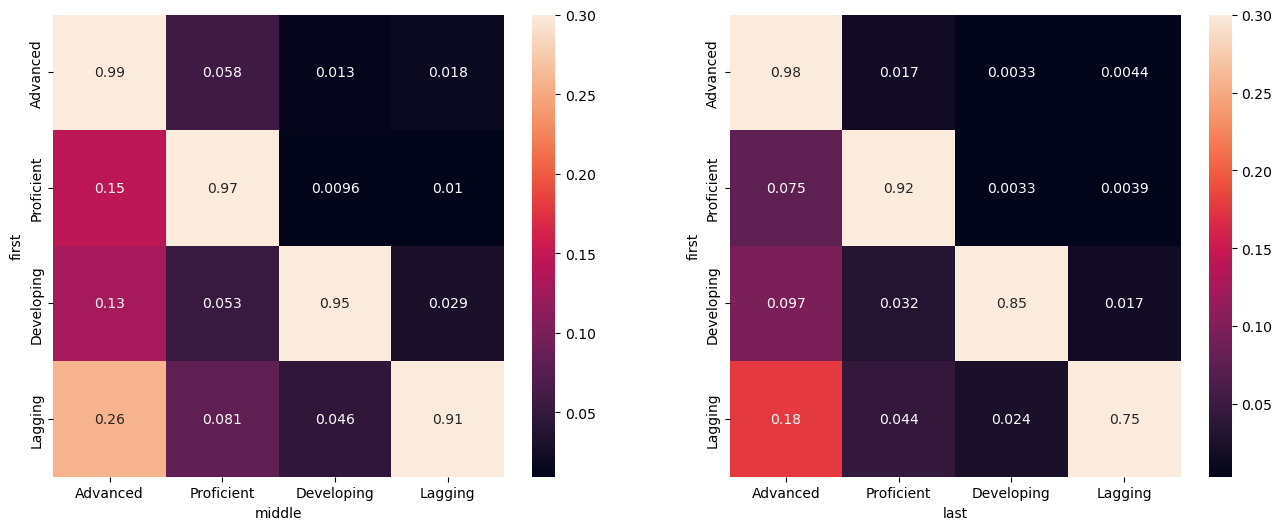

In [12]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16,6))
sns.heatmap(middle_df, vmax=0.3, annot=True, ax=ax[0])
sns.heatmap(last_df, vmax=0.3, annot=True, ax=ax[1])
plt.savefig('../../data/dropbox/LaborDivision/figs/conditional_distribution_first.pdf',bbox_inches='tight')

In [13]:
middle = []
first = []
for dgroup in stgroups:
    
    denominator_papers = return_denominator_papers(author_all, 'L',dgroup)
    denominator_cnt = len(denominator_papers)
    
    for ngroup in stgroups:
        
        numerator_middle = return_numerator(author_all, denominator_papers, 'M', ngroup)
        pcond_middle = numerator_middle/denominator_cnt
        middle.append([dgroup, ngroup, pcond_middle])

        numerator_first = return_numerator(author_all, denominator_papers, 'F', ngroup)
        pcond_first = numerator_first/denominator_cnt
        first.append([dgroup,ngroup,pcond_first])
       

In [14]:
middle_df = structure_resdf(middle, ['last','middle','p'])
first_df = structure_resdf(first, ['last','first','p'])

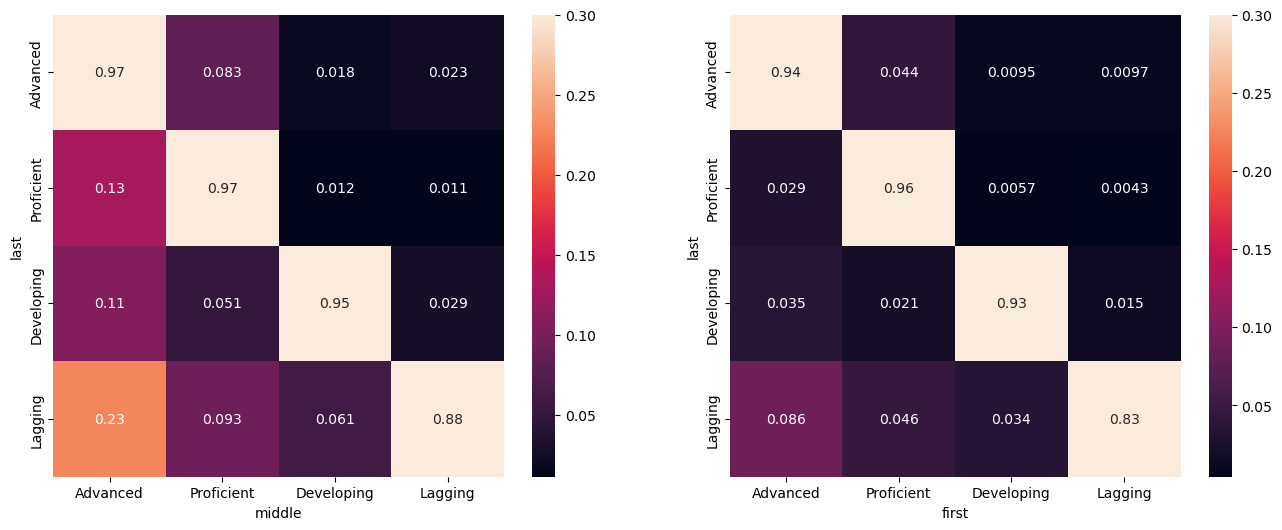

In [15]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16,6))
sns.heatmap(middle_df, vmax=0.3, annot=True, ax=ax[0])
sns.heatmap(first_df, vmax=0.3, annot=True, ax=ax[1])
plt.savefig('../../data/dropbox/LaborDivision/figs/conditional_distribution_last.pdf',bbox_inches='tight')